# GSE171405: download and load

This notebook pulls the official public files for GEO series **GSE171405** and gets them ready for analysis.

The study profiled skin from people with recessive dystrophic epidermolysis bullosa (RDEB): biopsies from the edge of chronic wounds (**EBw**), intact skin from the same RDEB donors (**EBn**), and matched healthy control skin (**HC**). There are 18 samples in total (6 per group).

**This is microarray data, not RNA-seq.** It was measured on the Illumina HumanHT-12 v4 BeadChip. NCBI does not provide a generated RNA-seq count matrix for this series. The values we load are quantile-normalized intensities, which we will treat accordingly in later notebooks.

Each step below has a short explanation, then the code.


Install the Python packages this notebook needs. Colab already has most of them; this cell is safe to re-run.


In [1]:
import sys
%pip install -q pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


Set up folders for the downloaded files, figures, and result tables. In Colab they go under `/content`. If you are running this notebook from the project repo, they go into `data/raw`, `figures`, and `results`.


In [2]:
%matplotlib inline

from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    ROOT = Path("/content")
    DATA_DIR = ROOT / "data"
    FIG_DIR = ROOT / "figures"
    RES_DIR = ROOT / "results"
else:
    cwd = Path.cwd().resolve()
    ROOT = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_DIR = ROOT / "data" / "raw"
    FIG_DIR = ROOT / "figures"
    RES_DIR = ROOT / "results"

for path in (DATA_DIR, FIG_DIR, RES_DIR):
    path.mkdir(parents=True, exist_ok=True)

print("Running in Colab:", IN_COLAB)
print("Data folder:   ", DATA_DIR)
print("Figures folder:", FIG_DIR)
print("Results folder:", RES_DIR)


Running in Colab: False
Data folder:    /workspace/rdeb-gse171405/repo/data/raw
Figures folder: /workspace/rdeb-gse171405/repo/figures
Results folder: /workspace/rdeb-gse171405/repo/results


Download the official GEO files over HTTPS from NCBI's FTP. We use three files:

1. **Series matrix** — quantile-normalized expression plus the sample metadata (group, donor, diagnosis, tissue).
2. **Family SOFT** — includes the platform annotation that maps each numeric probe ID (Illumina Array_Address_Id) to a gene symbol.
3. **Non-normalized intensities** — used only for a QC check that plays a similar role to "library size" in RNA-seq.

These are the exact URLs a Colab notebook can fetch with `wget` or Python:

- https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/matrix/GSE171405_series_matrix.txt.gz
- https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/soft/GSE171405_family.soft.gz
- https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/suppl/GSE171405_non-normalized.txt.gz


In [3]:
import gzip
import urllib.request
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

GEO_URLS = {
    "series_matrix": (
        "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/matrix/"
        "GSE171405_series_matrix.txt.gz"
    ),
    "family_soft": (
        "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/soft/"
        "GSE171405_family.soft.gz"
    ),
    "nonnormalized": (
        "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE171nnn/GSE171405/suppl/"
        "GSE171405_non-normalized.txt.gz"
    ),
}

DEST = {
    "series_matrix": DATA_DIR / "GSE171405_series_matrix.txt.gz",
    "family_soft": DATA_DIR / "GSE171405_family.soft.gz",
    "nonnormalized": DATA_DIR / "GSE171405_non-normalized.txt.gz",
}


def download_file(url, dest, timeout=120):
    # Reuse a file that is already present and non-empty.
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        print(f"Already have {dest.name} ({dest.stat().st_size:,} bytes)")
        return dest
    print(f"Downloading {url}")
    request = urllib.request.Request(url, headers={"User-Agent": "rdeb-gse171405/0.1"})
    with urllib.request.urlopen(request, timeout=timeout) as response, dest.open("wb") as out:
        while True:
            chunk = response.read(1024 * 1024)
            if not chunk:
                break
            out.write(chunk)
    print(f"Saved {dest.name} ({dest.stat().st_size:,} bytes)")
    return dest


for key, url in GEO_URLS.items():
    download_file(url, DEST[key])


Already have GSE171405_series_matrix.txt.gz (4,624,894 bytes)
Already have GSE171405_family.soft.gz (7,897,502 bytes)
Already have GSE171405_non-normalized.txt.gz (5,021,508 bytes)


Read the series-matrix header and build a clean sample table. GEO stores things like diagnosis, tissue, and donor as "characteristics." We turn the tissue label into the paper's group names: **EBw** (RDEB wound), **EBn** (intact RDEB skin), and **HC** (healthy control).


In [4]:
def _strip_quotes(value):
    return value.strip().strip('"')


def assign_group(tissue):
    tissue = (tissue or "").strip().lower()
    if tissue == "wounded skin":
        return "EBw"
    if tissue == "normal skin":
        return "EBn"
    if tissue == "control skin":
        return "HC"
    return "unknown"


def parse_series_matrix_metadata(path):
    series_info = {}
    sample_columns = {}
    characteristic_rows = []
    description_rows = []
    open_fn = gzip.open if str(path).endswith(".gz") else open
    with open_fn(path, "rt", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            if line.startswith("!series_matrix_table_begin"):
                break
            if not line.startswith("!"):
                continue
            parts = line.rstrip("\n").split("\t")
            key = parts[0]
            values = [_strip_quotes(v) for v in parts[1:]]
            if key.startswith("!Series_") and values:
                field = key.replace("!Series_", "")
                series_info.setdefault(field, values[0])
            elif key.startswith("!Sample_characteristics"):
                characteristic_rows.append(values)
            elif key == "!Sample_description":
                description_rows.append(values)
            elif key.startswith("!Sample_") and values:
                sample_columns[key.replace("!Sample_", "")] = values

    samples = pd.DataFrame({"sample_id": sample_columns.get("geo_accession", [])})
    samples["title"] = sample_columns.get("title", [""] * len(samples))
    samples["source_name"] = sample_columns.get("source_name_ch1", [""] * len(samples))
    samples["platform_id"] = sample_columns.get("platform_id", [""] * len(samples))

    for row in characteristic_rows:
        field_name = "characteristic"
        parsed = []
        for item in row:
            if ":" in item:
                name, value = item.split(":", 1)
                field_name = name.strip()
                parsed.append(value.strip())
            else:
                parsed.append(item)
        samples[field_name] = parsed

    if len(description_rows) >= 1:
        samples["array_label"] = [v.strip() for v in description_rows[0]]
    if len(description_rows) >= 2:
        samples["sample_label"] = [v.strip() for v in description_rows[1]]

    samples["group"] = samples["tissue"].map(assign_group) if "tissue" in samples.columns else "unknown"
    preferred = [
        "sample_id", "sample_label", "group", "donor", "diagnosis", "tissue",
        "title", "source_name", "array_label", "platform_id",
    ]
    ordered = [c for c in preferred if c in samples.columns] + [
        c for c in samples.columns if c not in preferred
    ]
    return samples[ordered], series_info


samples, series_info = parse_series_matrix_metadata(DEST["series_matrix"])
print("Series:", series_info.get("title", ""))
print("GEO accession:", series_info.get("geo_accession", ""))
print("Type:", series_info.get("type", ""))
print("Platform:", series_info.get("platform_id", ""))
print("PubMed ID:", series_info.get("pubmed_id", ""))
print()
print(f"Sample table: {samples.shape[0]} samples × {samples.shape[1]} columns")
samples


Series: Gene expression analysis in recessive dystrophic epidermolysis bullosa skin highlights drug repurposing opportunities to improve wound healing
GEO accession: GSE171405
Type: Expression profiling by array
Platform: GPL28270
PubMed ID: 34694680

Sample table: 18 samples × 10 columns


,sample_id,sample_label,group,donor,diagnosis,tissue,title,source_name,array_label,platform_id
0,GSM5224960,EB1w,EBw,EB1,recessive dystrophic epidermolysis bullosa,wounded skin,wounded with EBw [EB1w],Epidermolysis Bullosa Wounded,7196780027_A_Grn,GPL28270
1,GSM5224961,EB1n,EBn,EB1,recessive dystrophic epidermolysis bullosa,normal skin,normal with EBn [EB1n],Epidermolysis Bullosa Normal,7196780027_B_Grn,GPL28270
2,GSM5224962,C1,HC,C1,healthy,control skin,control with HC [C1],Control,7196780027_C_Grn,GPL28270
3,GSM5224963,EB2w,EBw,EB2,recessive dystrophic epidermolysis bullosa,wounded skin,wounded with EBw [EB2w],Epidermolysis Bullosa Wounded,7196780027_D_Grn,GPL28270
4,GSM5224964,EB2n,EBn,EB2,recessive dystrophic epidermolysis bullosa,normal skin,normal with EBn [EB2n],Epidermolysis Bullosa Normal,7196780027_E_Grn,GPL28270
5,GSM5224965,C2,HC,C2,healthy,control skin,control with HC [C2],Control,7196780027_F_Grn,GPL28270
6,GSM5224966,EB3w,EBw,EB3,recessive dystrophic epidermolysis bullosa,wounded skin,wounded with EBw [EB3w],Epidermolysis Bullosa Wounded,7196780027_G_Grn,GPL28270
7,GSM5224967,EB3n,EBn,EB3,recessive dystrophic epidermolysis bullosa,normal skin,normal with EBn [EB3n],Epidermolysis Bullosa Normal,7196780027_H_Grn,GPL28270
8,GSM5224968,C3,HC,C3,healthy,control skin,control with HC [C3],Control,7196780027_I_Grn,GPL28270
9,GSM5224969,EB4w,EBw,EB4,recessive dystrophic epidermolysis bullosa,wounded skin,wounded with EBw [EB4w],Epidermolysis Bullosa Wounded,7196780027_J_Grn,GPL28270


Load the quantile-normalized expression matrix. Rows are numeric Illumina **Array_Address_Id** probe IDs (not Ensembl or Entrez IDs). Columns are GEO sample accessions (GSM…).


In [5]:
def load_series_matrix_expression(path):
    lines = []
    open_fn = gzip.open if str(path).endswith(".gz") else open
    with open_fn(path, "rt", encoding="utf-8", errors="replace") as handle:
        in_table = False
        for line in handle:
            if line.startswith("!series_matrix_table_begin"):
                in_table = True
                continue
            if line.startswith("!series_matrix_table_end"):
                break
            if in_table:
                lines.append(line)
    expr = pd.read_csv(StringIO("".join(lines)), sep="\t", index_col=0)
    expr.index = expr.index.astype(str)
    expr.columns = [str(c).strip().strip('"') for c in expr.columns]
    return expr.apply(pd.to_numeric, errors="coerce")


expr = load_series_matrix_expression(DEST["series_matrix"])
# Keep samples in the same order as the metadata table
expr = expr.loc[:, samples["sample_id"]]

print(f"Expression matrix shape: {expr.shape[0]:,} probes × {expr.shape[1]} samples")
print("Index name / gene ID type (raw IDs): Illumina Array_Address_Id (numeric)")
print("First probe IDs:", list(expr.index[:8]))
print("Value range: {:.3f} to {:.3f}".format(expr.min().min(), expr.max().max()))
print("Per-sample median (normalized intensity):")
print(expr.median().round(3).to_string())
expr.iloc[:5, :6]


Expression matrix shape: 47,323 probes × 18 samples
Index name / gene ID type (raw IDs): Illumina Array_Address_Id (numeric)
First probe IDs: ['10008', '10010', '10014', '10017', '10019', '10020', '10021', '10025']
Value range: 4.732 to 14.971
Per-sample median (normalized intensity):


GSM5224960    5.541
GSM5224961    5.541
GSM5224962    5.541
GSM5224963    5.541
GSM5224964    5.541
GSM5224965    5.541
GSM5224966    5.541
GSM5224967    5.541
GSM5224968    5.542
GSM5224969    5.542
GSM5224970    5.541
GSM5224971    5.542
GSM5224972    5.541
GSM5224973    5.541
GSM5224974    5.541
GSM5224975    5.540
GSM5224976    5.541
GSM5224977    5.541


,GSM5224960,GSM5224961,GSM5224962,GSM5224963,GSM5224964,GSM5224965
ID_REF,,,,,,
10008,9.348345,9.757513,9.936694,9.110002,10.015261,9.757144
10010,5.300138,5.230180,5.306630,5.216239,5.330911,5.440398
10014,5.251558,5.189196,5.187551,5.295635,5.211023,5.306052
10017,5.405478,5.277607,5.326779,5.205825,5.331498,5.368889
10019,5.682925,8.667635,7.965629,6.176186,7.843832,7.651480


Load the platform annotation from the family SOFT file so we can see what those numeric probe IDs mean. On this platform (GPL28270) the official columns are `ID` (Array_Address_Id) and `ORF` (gene symbol). Some symbols are older aliases.


In [6]:
def load_platform_annotation_from_soft(path):
    lines = []
    open_fn = gzip.open if str(path).endswith(".gz") else open
    with open_fn(path, "rt", encoding="utf-8", errors="replace") as handle:
        in_table = False
        for line in handle:
            if line.startswith("!platform_table_begin"):
                in_table = True
                continue
            if line.startswith("!platform_table_end"):
                break
            if in_table:
                lines.append(line)
    annot = pd.read_csv(StringIO("".join(lines)), sep="\t")
    annot = annot.rename(columns={"ID": "array_address_id", "ORF": "gene_symbol"})
    annot["array_address_id"] = annot["array_address_id"].astype(str)
    return annot


annot = load_platform_annotation_from_soft(DEST["family_soft"])
overlap = annot["array_address_id"].isin(expr.index).sum()
print(f"Annotation table: {annot.shape[0]:,} rows, columns = {list(annot.columns)}")
print(f"Unique gene symbols: {annot['gene_symbol'].nunique():,}")
print(f"Probes in both the expression matrix and the annotation: {overlap:,}")
print("Gene ID type: Illumina HumanHT-12 v4 Array_Address_Id, annotated to gene symbols (ORF).")
print("These are not Ensembl IDs or Entrez Gene IDs.")
annot.head(10)


Annotation table: 47,323 rows, columns = ['array_address_id', 'gene_symbol']
Unique gene symbols: 34,694
Probes in both the expression matrix and the annotation: 47,323
Gene ID type: Illumina HumanHT-12 v4 Array_Address_Id, annotated to gene symbols (ORF).
These are not Ensembl IDs or Entrez Gene IDs.


,array_address_id,gene_symbol
0,6450255,7A5
1,2570615,A1BG
2,6370619,A1BG
3,2600039,A1CF
4,2650615,A1CF
5,5340672,A1CF
6,2000519,A26C3
7,3870044,A26C3
8,7050209,A26C3
9,1580181,A2BP1


Sanity checks, all in one place:

- **Shape** of the expression matrix and sample table.
- **Gene ID type**, and how completely the annotation overlaps the matrix.
- **Library-size analogue:** total raw intensity per sample from the non-normalized file. This is not sequencing depth (there is none here), but it is a useful check that no array looks grossly under- or over-loaded.
- **Group-count summary:** how many samples are in EBw, EBn, and HC, and whether each RDEB donor has both a wound and an intact-skin sample.


=== Shapes ===
Expression matrix: 47,323 probes × 18 samples
Sample table:      18 samples × 10 columns
Annotation:        47,323 probes, 34,694 unique symbols
Non-normalized:    48,210 rows × 18 arrays (includes 887 extra control probes not in the series matrix)

=== Gene ID type ===
Illumina HumanHT-12 v4 Array_Address_Id (numeric bead/probe address).
Overlap with platform annotation: 47,323 / 47,323 probes.
Example mappings:
                   gene_symbol
array_address_id              
10008                     RERE
10010                HS.584291
10014             LOC100132838
10017                LOC645218
10019                   RNF165
10020                HS.565863
10021                   MIR558
10025                    DLEC1

=== Group-count summary ===
       n_samples  n_donors
group                     
EBw            6         6
EBn            6         6
HC             6         6

Donors by group:
group  EBn  EBw  HC
donor              
C1       0    0   1
C2       0    0 


Saved figure: /workspace/rdeb-gse171405/repo/figures/01_qc_overview.png


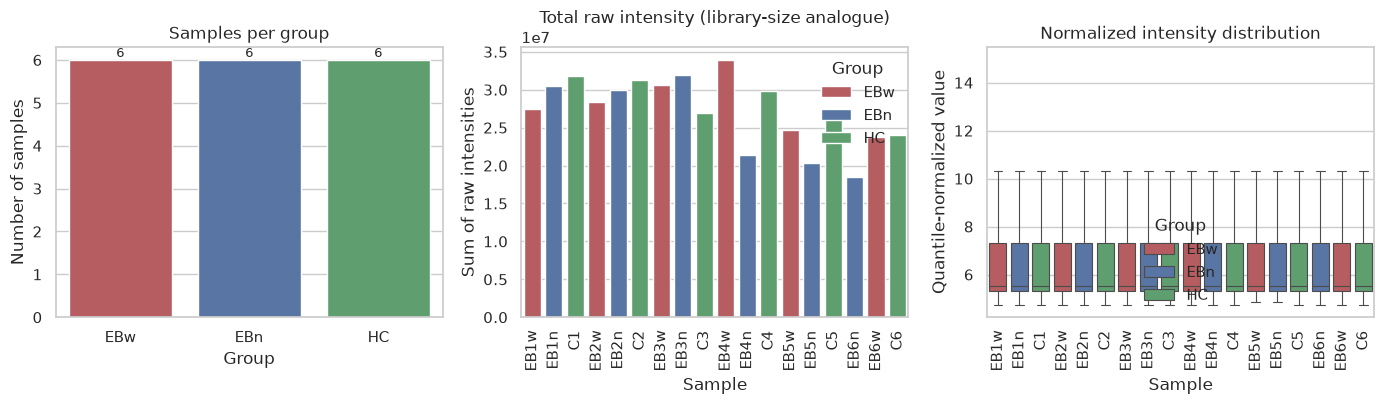

In [7]:
def load_nonnormalized(path):
    # Read probe IDs as strings. This file includes control probes with IDs like
    # "1820564.1"; if pandas infers a float column, official IDs become "5270161.0"
    # and no longer match the series matrix.
    table = pd.read_csv(
        path,
        sep="\t",
        dtype={0: str},
        compression="gzip" if str(path).endswith(".gz") else None,
    )
    table = table.rename(columns={table.columns[0]: "array_address_id"})
    table["array_address_id"] = table["array_address_id"].astype(str)
    table = table.set_index("array_address_id")
    table.columns = [str(c).strip() for c in table.columns]
    return table.apply(pd.to_numeric, errors="coerce")


raw = load_nonnormalized(DEST["nonnormalized"])
# Map array labels (e.g. 7196780027_A_Grn) back to GSM sample IDs
label_to_sample = dict(zip(samples["array_label"], samples["sample_id"]))
missing_labels = [c for c in raw.columns if c not in label_to_sample]
if missing_labels:
    print(f"Note: {len(missing_labels)} non-normalized columns had no metadata match.")

raw_by_sample = raw.rename(columns=label_to_sample)
# Library-size analogue: sum of raw intensities, using only probes that are also in the normalized matrix
shared_probes = raw_by_sample.index.intersection(expr.index)
if len(shared_probes) == 0:
    raise RuntimeError(
        "No probe IDs overlapped between the non-normalized file and the series matrix. "
        "This usually means probe IDs were read as floats (e.g. '5270161.0')."
    )
library_size = raw_by_sample.loc[shared_probes, samples["sample_id"]].sum(axis=0)
library_size.name = "total_raw_intensity"

sample_qc = samples.set_index("sample_id").copy()
sample_qc["n_probes_normalized"] = expr.notna().sum()
sample_qc["median_normalized"] = expr.median()
sample_qc["total_raw_intensity"] = library_size
sample_qc["missing_values"] = expr.isna().sum()
sample_qc = sample_qc.reset_index()

print("=== Shapes ===")
print(f"Expression matrix: {expr.shape[0]:,} probes × {expr.shape[1]} samples")
print(f"Sample table:      {samples.shape[0]} samples × {samples.shape[1]} columns")
print(f"Annotation:        {annot.shape[0]:,} probes, {annot['gene_symbol'].nunique():,} unique symbols")
print(
    f"Non-normalized:    {raw.shape[0]:,} rows × {raw.shape[1]} arrays "
    f"(includes {raw.shape[0] - expr.shape[0]:,} extra control probes not in the series matrix)"
)

print("\n=== Gene ID type ===")
print("Illumina HumanHT-12 v4 Array_Address_Id (numeric bead/probe address).")
print(f"Overlap with platform annotation: {overlap:,} / {expr.shape[0]:,} probes.")
print("Example mappings:")
print(
    annot.set_index("array_address_id")
    .loc[list(expr.index[:8]), ["gene_symbol"]]
    .to_string()
)

print("\n=== Group-count summary ===")
group_counts = (
    samples.groupby("group")
    .agg(n_samples=("sample_id", "size"), n_donors=("donor", "nunique"))
    .reindex(["EBw", "EBn", "HC"])
)
print(group_counts.to_string())
print("\nDonors by group:")
print(
    samples.pivot_table(index="donor", columns="group", values="sample_id", aggfunc="count")
    .fillna(0)
    .astype(int)
    .to_string()
)

print("\n=== Library-size analogue (total raw intensity on 47,323 official probes) ===")
print(
    sample_qc[
        ["sample_id", "sample_label", "group", "donor", "total_raw_intensity", "median_normalized", "missing_values"]
    ].to_string(index=False)
)
print()
print(sample_qc.groupby("group")["total_raw_intensity"].describe().reindex(["EBw", "EBn", "HC"]).to_string())
print()
print("Missing values in the normalized matrix:", int(expr.isna().sum().sum()))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

group_order = ["EBw", "EBn", "HC"]
palette = {"EBw": "#c44e52", "EBn": "#4c72b0", "HC": "#55a868"}

sns.countplot(
    data=samples, x="group", order=group_order, hue="group",
    palette=palette, legend=False, ax=axes[0],
)
axes[0].set_title("Samples per group")
axes[0].set_xlabel("Group")
axes[0].set_ylabel("Number of samples")
for p in axes[0].patches:
    axes[0].annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center", va="bottom", fontsize=9,
    )

qc_plot = sample_qc.copy()
qc_plot["short"] = qc_plot["sample_label"].fillna(qc_plot["sample_id"])
sns.barplot(
    data=qc_plot, x="short", y="total_raw_intensity", hue="group",
    hue_order=group_order, palette=palette, dodge=False, ax=axes[1],
)
axes[1].set_title("Total raw intensity (library-size analogue)")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Sum of raw intensities")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend(title="Group", frameon=False)

expr_long = expr.melt(var_name="sample_id", value_name="normalized_intensity")
expr_long = expr_long.merge(samples[["sample_id", "sample_label", "group"]], on="sample_id", how="left")
sns.boxplot(
    data=expr_long, x="sample_label", y="normalized_intensity", hue="group",
    hue_order=group_order, palette=palette, dodge=False, ax=axes[2],
    fliersize=0, linewidth=0.8,
)
axes[2].set_title("Normalized intensity distribution")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Quantile-normalized value")
axes[2].tick_params(axis="x", rotation=90)
axes[2].legend(title="Group", frameon=False)

fig.tight_layout()
fig_path = FIG_DIR / "01_qc_overview.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"\nSaved figure: {fig_path}")
plt.show()


Save the clean sample table, probe annotation, and a short QC summary so later notebooks can reuse them without parsing GEO files again.


In [8]:
samples_path = RES_DIR / "sample_table.csv"
annot_path = RES_DIR / "probe_annotation.csv"
qc_path = RES_DIR / "sample_qc.csv"
summary_path = RES_DIR / "sanity_summary.txt"

samples.to_csv(samples_path, index=False)
annot.to_csv(annot_path, index=False)
sample_qc.to_csv(qc_path, index=False)

lines = [
    "GSE171405 download-and-load sanity summary",
    f"Series: {series_info.get('title', '')}",
    f"GEO: {series_info.get('geo_accession', 'GSE171405')}",
    f"Type: {series_info.get('type', '')}",
    f"Platform: {series_info.get('platform_id', 'GPL28270')} (Illumina HumanHT-12 v4, Array_Address_Id)",
    f"PubMed: {series_info.get('pubmed_id', '34694680')}",
    "",
    f"Expression matrix: {expr.shape[0]} probes × {expr.shape[1]} samples",
    f"Gene ID type: Illumina Array_Address_Id (numeric). Annotated gene symbols: {annot['gene_symbol'].nunique()} unique.",
    f"Annotation overlap: {overlap} / {expr.shape[0]} probes.",
    f"Non-normalized extra control probes: {raw.shape[0] - expr.shape[0]}",
    f"Missing values in normalized matrix: {int(expr.isna().sum().sum())}",
    "",
    "Group counts:",
    group_counts.to_string(),
    "",
    "Library-size analogue (total raw intensity) by group:",
    sample_qc.groupby("group")["total_raw_intensity"].describe().reindex(["EBw", "EBn", "HC"]).to_string(),
    "",
]
summary_path.write_text("\n".join(lines) + "\n")
print("\n".join(lines))
print("Wrote:")
for path in (samples_path, annot_path, qc_path, summary_path, FIG_DIR / "01_qc_overview.png"):
    print(f"  {path} ({path.stat().st_size:,} bytes)")


GSE171405 download-and-load sanity summary
Series: Gene expression analysis in recessive dystrophic epidermolysis bullosa skin highlights drug repurposing opportunities to improve wound healing
GEO: GSE171405
Type: Expression profiling by array
Platform: GPL28270 (Illumina HumanHT-12 v4, Array_Address_Id)
PubMed: 34694680

Expression matrix: 47323 probes × 18 samples
Gene ID type: Illumina Array_Address_Id (numeric). Annotated gene symbols: 34694 unique.
Annotation overlap: 47323 / 47323 probes.
Non-normalized extra control probes: 887
Missing values in normalized matrix: 0

Group counts:
       n_samples  n_donors
group                     
EBw            6         6
EBn            6         6
HC             6         6

Library-size analogue (total raw intensity) by group:
       count          mean           std           min           25%           50%           75%           max
group                                                                                                  

## What we have now

- 18 samples, 6 in each group (EBw, EBn, HC), with donor IDs so we can later account for the paired RDEB wound vs intact-skin design.
- A 47,323-probe quantile-normalized expression matrix, with probe IDs mapped to gene symbols.
- A QC pass on shapes, ID type, and per-sample total raw intensity.

Next up: differential expression between EBw, EBn, and HC, using a method that is appropriate for microarray intensities (not RNA-seq count tools such as DESeq2).
